In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter
from pathlib import Path
import math
from scipy.interpolate import CubicSpline 
import tol_colors as tc

import tools
import my_plot as mplt

from plot_utils import set_size, set_colors, width_jcap, sci_formatter
plt.style.use('my_style.mplstyle')

In [2]:
plt.rcParams['font.size']=14

In [3]:
def extract_PSTE(folder_path, ellmax, ymax, zcon):
    """Extract power spectra from the output of the FH code. """
    folder = Path(folder_path) / "FH" / "yn_T_aniso_system" 
    #file_path = next(folder.glob(f"power_spectra_ymax{ymax}_lmax{ellmax}_adiabatic_nmax_{zcon}.dat"))
    file_path = next(folder.glob(f"power_spectra_ymax{ymax}_lmax{ellmax}_adiabatic_zcon_{zcon}.dat"))
    #file_path = next(folder.glob(f"power_spectra_ymax{ymax}_lmax{ellmax}.dat"))


    ell = []
    TE = []
    muE = []
    yE = []

    ell = np.loadtxt(file_path, comments='#')[:, 0]
    TE = np.loadtxt(file_path, comments='#')[:, 2]
    muE = np.loadtxt(file_path, comments='#')[:, 8]
    yE = np.loadtxt(file_path, comments='#')[:, 9]

    return np.array(ell), np.array(TE), np.array(yE), np.array(muE)

In [4]:
ell , TE, yE, muE = extract_PSTE("../Data/Dark-photons/outputs_dp_PS/batch/",15,5,"001")
_ , TE_1, yE_1, muE_1 = extract_PSTE("../Data/Dark-photons/outputs_dp_PS/batch/",15,5,"002")
_ , TE_2, yE_2, muE_2 = extract_PSTE("../Data/Dark-photons/outputs_dp_PS/batch/",15,5,"003")
_ , TE_3, yE_3, muE_3 = extract_PSTE("../Data/Dark-photons/outputs_dp_PS/batch/",15,5,"004")



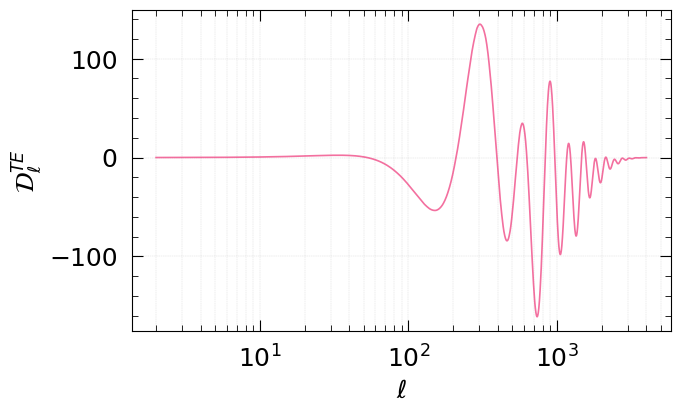

In [5]:
colors = tc.colorsets['vibrant']
fig, ax = plt.subplots(1, 1, figsize=mplt.set_size(mplt.width))

ax.plot(ell, TE, color=colors[3], alpha=0.7, linestyle="-", label="TE")


mplt.set_ticks(ax)
mplt.set_labels(ax, x_label="$\\ell$", x_log=True, y_label="$\\mathcal{D}_\\ell^{{TE}}$", y_log=False, title=None)

#plt.savefig('outputs/TE.pdf', dpi=300, bbox_inches="tight")

#ax.legend()
plt.show()


Ehe following two plots are for me only, we are not including the first line in the paper. But they nicely show how very early energy injections thermalise immediatly, what we sTE it is basically only a very small signal due to numerical noise probably

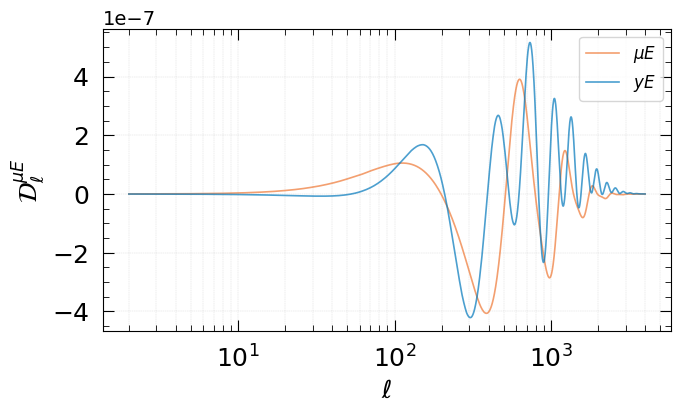

In [6]:
fig, ax = plt.subplots(1, 1, figsize=mplt.set_size(mplt.width))

ax.plot(ell, muE, color=colors[0], alpha=0.7, linestyle="-", label="$\\mu E$")
ax.plot(ell, yE, color=colors[1], alpha=0.7, linestyle="-", label="$y E$")

mplt.set_ticks(ax)
mplt.set_labels(ax, x_label="$\\ell$", x_log=True, y_label="$\\mathcal{D}_{\\ell}^{{\\mu E}}$", y_log=False, title=None)


ax.legend()
plt.show()

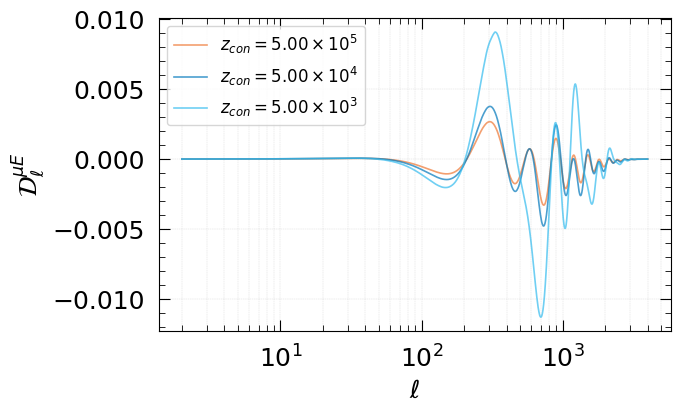

In [7]:
fig, ax = plt.subplots(1, 1, figsize=mplt.set_size(mplt.width))


ax.plot(ell, muE_1, color=colors[0], alpha=0.7, linestyle="-", label=f"$z_{{con}} = ${tools.sci_notation(5e5)}")
ax.plot(ell, muE_2, color=colors[1], alpha=0.7, linestyle="-", label=f"$z_{{con}} = ${tools.sci_notation(5e4)}")
ax.plot(ell, muE_3, color=colors[2], alpha=0.7, linestyle="-", label=f"$z_{{con}} = ${tools.sci_notation(5e3)}")

mplt.set_ticks(ax)
mplt.set_labels(ax, x_label="$\\ell$", x_log=True, y_label="$\\mathcal{D}_{\\ell}^{{\\mu E}}$", y_log=False, title=None)

#plt.savefig('outputs/muE.pdf', dpi=300, bbox_inches="tight")


ax.legend()
plt.show()

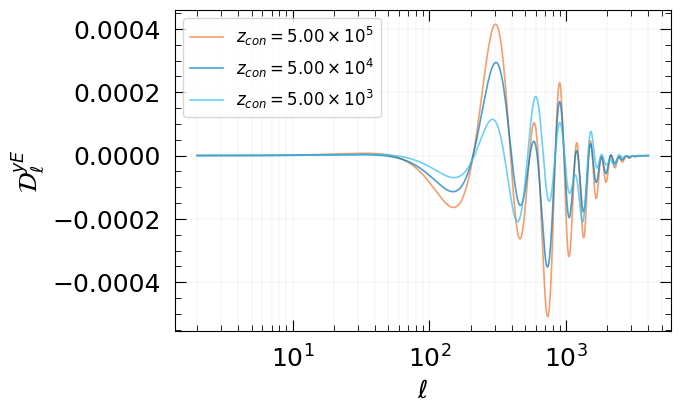

In [8]:
fig, ax = plt.subplots(1, 1, figsize=mplt.set_size(mplt.width))


ax.plot(ell, yE_1, color=colors[0], alpha=0.7, linestyle="-", label=f"$z_{{con}} = ${tools.sci_notation(5e5)}")
ax.plot(ell, yE_2, color=colors[1], alpha=0.7, linestyle="-", label=f"$z_{{con}} = ${tools.sci_notation(5e4)}")
ax.plot(ell, yE_3, color=colors[2], alpha=0.7, linestyle="-", label=f"$z_{{con}} = ${tools.sci_notation(5e3)}")


mplt.set_ticks(ax)
mplt.set_labels(ax, x_label="$\\ell$", x_log=True, y_label="$\\mathcal{D}_{\\ell}^{{y E}}$", y_log=False, title=None)

#plt.savefig('outputs/yE.pdf', dpi=300, bbox_inches="tight")

ax.legend()
plt.show()

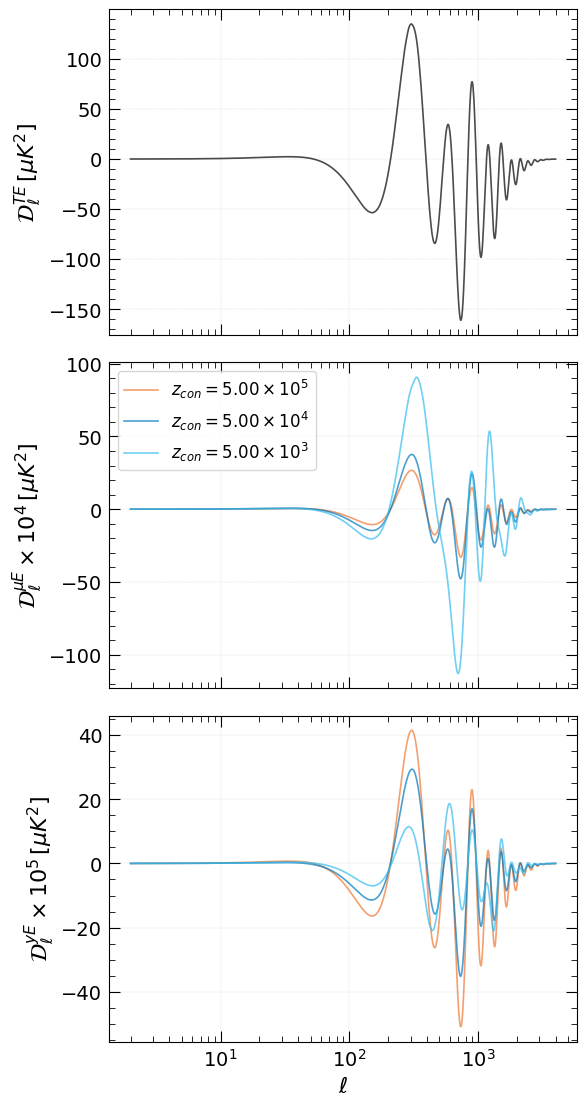

In [9]:

fig, ax = plt.subplots(3, 1, figsize=set_size(width_jcap, 1, (3,1)),sharex='col')


ax[0].plot(ell, TE, color="black", alpha=0.7, linestyle="-" , linewidth=1.2,  label="TE")


ax[1].plot(ell, muE_1*10000, color=colors[0], alpha=0.7, linestyle="-" , linewidth=1.2, label=f"$z_{{con}} = ${tools.sci_notation(5e5)}")
ax[1].plot(ell, muE_2*10000, color=colors[1], alpha=0.7, linestyle="-", linewidth=1.2, label=f"$z_{{con}} = ${tools.sci_notation(5e4)}")
ax[1].plot(ell, muE_3*10000, color=colors[2], alpha=0.7, linestyle="-", linewidth=1.2, label=f"$z_{{con}} = ${tools.sci_notation(5e3)}")

ax[2].plot(ell, yE_1*100000, color=colors[0], alpha=0.7, linestyle="-", linewidth=1.2)
ax[2].plot(ell, yE_2*100000, color=colors[1], alpha=0.7, linestyle="-", linewidth=1.2)
ax[2].plot(ell, yE_3*100000, color=colors[2], alpha=0.7, linestyle="-", linewidth=1.2)



for a in ax:
    a.set_xscale('log')

ax[0].tick_params(labelbottom=False)
ax[1].tick_params(labelbottom=False)

ax[0].set_ylabel("$\\mathcal{D}_\\ell^{{TE}} \\, [\\mu K^2]$")
ax[1].set_ylabel("$\\mathcal{D}_{\\ell}^{{\\mu E}} \\times 10^4 \\, [\\mu K^2]$")
ax[2].set_ylabel("$\\mathcal{D}_{\\ell}^{{y E}} \\times 10^5 \\, [\\mu K^2]$")
ax[2].set_xlabel("$\\ell$")

ax[1].legend()

plt.savefig('outputs/muE_yE.pdf', dpi=300, bbox_inches="tight")
plt.show()

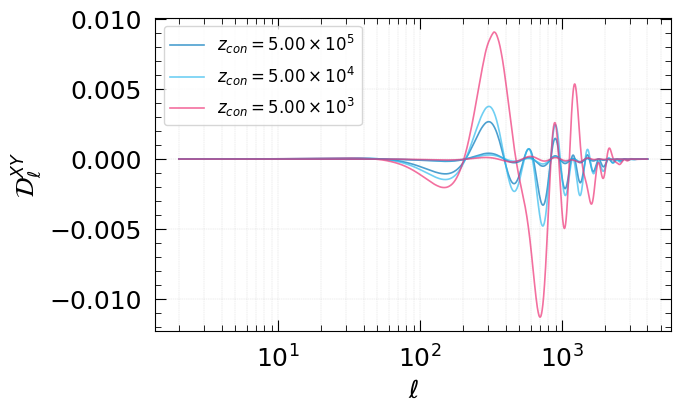

In [10]:
fig, ax = plt.subplots(1, 1, figsize=mplt.set_size(mplt.width))


ax.plot(ell, muE_1, color=colors[1], alpha=0.7, linestyle="-", label=f"$z_{{con}} = ${tools.sci_notation(5e5)}")
ax.plot(ell, muE_2, color=colors[2], alpha=0.7, linestyle="-", label=f"$z_{{con}} = ${tools.sci_notation(5e4)}")
ax.plot(ell, muE_3, color=colors[3], alpha=0.7, linestyle="-", label=f"$z_{{con}} = ${tools.sci_notation(5e3)}")

ax.plot(ell, yE_1, color=colors[1], alpha=0.7, linestyle="-")
ax.plot(ell, yE_2, color=colors[2], alpha=0.7, linestyle="-")
ax.plot(ell, yE_3, color=colors[3], alpha=0.7, linestyle="-")


mplt.set_ticks(ax)
mplt.set_labels(ax, x_label="$\\ell$", x_log=True, y_label="$\\mathcal{D}_{\\ell}^{{XY}} $", y_log=False, title=None)

# ax.annotate("$yE$", xy=(5, 3e-4), fontsize=12)
# ax.annotate("$\\mu E$", xy=(5, 2e-2), fontsize=12)


ax.legend()
plt.show()

In [11]:
def extract_PS(folder_path, index_max):
    """Extract scattering basis transfer function data from files in a folder """
    folder = Path(folder_path) / "batch" / "FH" / "yn_T_aniso_system" 

    ell = []
    TE = []
    muE = []
    yE = []

    
    for i in range(index_max):
        file_path = next(folder.glob(f"power_spectra_ymax15_lmax15_adiabatic_zcon_{i+1:03d}.dat"))

        if i == 0:
            ell.extend(np.loadtxt(file_path, comments='#')[:, 0])

        TE.append(np.loadtxt(file_path, comments='#')[:, 6])
        muE.append(np.loadtxt(file_path, comments='#')[:, 8])
        yE.append(np.loadtxt(file_path, comments='#')[:, 9])

    return np.array(ell), np.array(TE),np.array(yE), np.array(muE)

In [12]:
ell_1 , TE, yE, muE = extract_PS("../Data/Dark-photons/outputs_dp_PS-fullbatch",6)


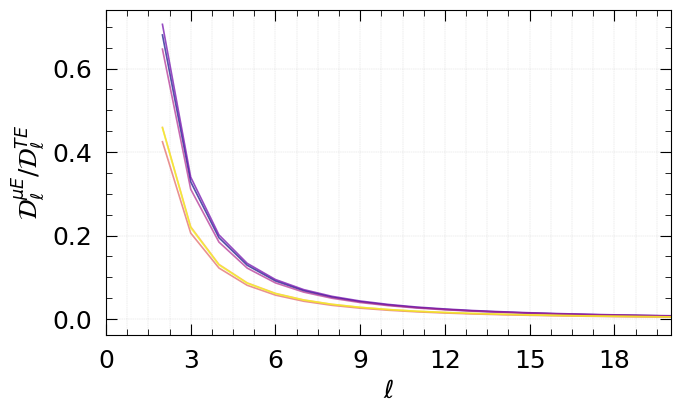

In [13]:
# SMALL L ONLY

fig, ax = plt.subplots(1, 1, figsize=mplt.set_size(mplt.width))

colors = mplt.set_colors(6, palette="plasma")

for i in range(len(TE)):
    ax.plot(ell_1, muE[i]/TE[i], color=colors(i), alpha=0.7, linestyle="-", label=f"muE, zcon={tools.sci_notation(5e5/(10**i))}")
    #ax.plot(ell_1[0],-muE[i], color=colors(i), alpha=0.7, linestyle="--")

    #ax.plot(ell_1[0], yE[i], color=colors(i), alpha=0.7, linestyle="-.", label=f"yE, zcon={tools.sci_notation(5e5/(10**i))}")

mplt.set_ticks(ax)
mplt.set_labels(ax, x_label="$\\ell$", x_log=False, y_label="$\\mathcal{D}_{\\ell}^{{\\mu E}} / \\mathcal{D}_{\\ell}^{{TE}}$", y_log=False, title=None)

# ax.annotate("$yE$", xy=(5, 3e-4), fontsize=12)
# ax.annotate("$\\mu E$", xy=(5, 2e-2), fontsize=12)

ax.set_xlim(0,20)
#ax.legend(fontsize=10)
plt.show()

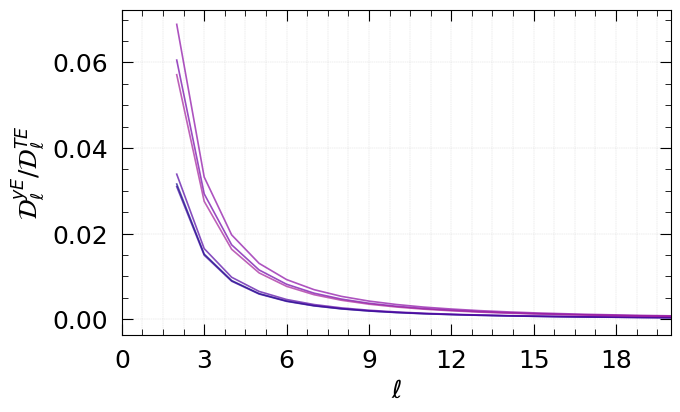

In [14]:
fig, ax = plt.subplots(1, 1, figsize=mplt.set_size(mplt.width))

colors = mplt.set_colors(15, palette="plasma")

for i in range(len(TE)):
    ax.plot(ell_1, yE[i]/TE[i], color=colors(i), alpha=0.7, linestyle="-", label=f"muE, zcon={tools.sci_notation(5e5/(10**i))}")
    #ax.plot(ell[0], yE[i], color=colors(i), alpha=0.7, linestyle="-.", label=f"yE, zcon={tools.sci_notation(5e5/(10**i))}")

mplt.set_ticks(ax)
mplt.set_labels(ax, x_label="$\\ell$", x_log=False, y_label="$\\mathcal{D}_{\\ell}^{{y E}} / \\mathcal{D}_{\\ell}^{{TE}}$", y_log=False, title=None)

# ax.annotate("$yE$", xy=(5, 3e-4), fontsize=12)
# ax.annotate("$\\mu E$", xy=(5, 2e-2), fontsize=12)

ax.set_xlim(0,20)
#ax.legend(fontsize=10)
plt.show()

In [15]:

def truncated_cmap(cmap_name, minval=0.1, maxval=0.9, n=15):
    cmap = plt.cm.get_cmap(cmap_name)
    return lambda i: cmap(minval + (maxval - minval) * i / (n - 1))

import tol_colors as tc

colors = tc.rainbow_WhBr_r.resampled(15)

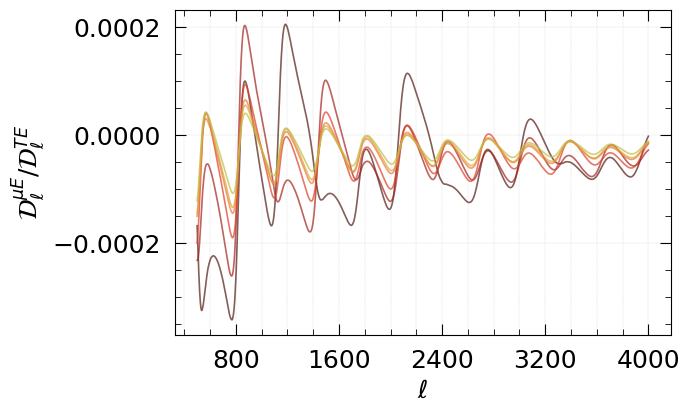

In [16]:
# large l using a mask

mask = (ell >= 500) & (ell <= ell[-1])

fig, ax = plt.subplots(1, 1, figsize=mplt.set_size(mplt.width))



for i in range(len(TE)):
    ax.plot(ell_1[mask], muE[i][mask]/TE[i][mask], color=colors(i), alpha=0.7, linestyle="-", label=f"muE, zcon={tools.sci_notation(5e5/(10**i))}")
    #ax.plot(ell_1[0],-muE[i], color=colors(i), alpha=0.7, linestyle="--")

    #ax.plot(ell_1[0], yE[i], color=colors(i), alpha=0.7, linestyle="-.", label=f"yE, zcon={tools.sci_notation(5e5/(10**i))}")

mplt.set_ticks(ax)
mplt.set_labels(ax, x_label="$\\ell$", x_log=False, y_label="$\\mathcal{D}_{\\ell}^{{\\mu E}} / \\mathcal{D}_{\\ell}^{{TE}}$", y_log=False, title=None)

# ax.annotate("$yE$", xy=(5, 3e-4), fontsize=12)
# ax.annotate("$\\mu E$", xy=(5, 2e-2), fontsize=12)

#plt.savefig('outputs/muE_TE.pdf', dpi=300, bbox_inches="tight")


#ax.legend(fontsize=10)
plt.show()


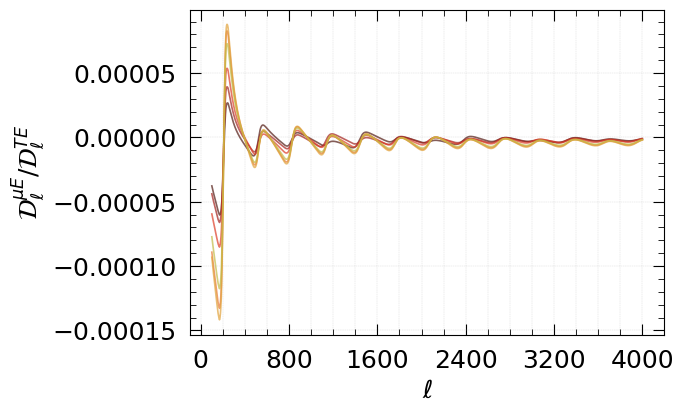

In [17]:
# large l using a mask

mask = (ell >= 100) & (ell <= ell[-1])

fig, ax = plt.subplots(1, 1, figsize=mplt.set_size(mplt.width))


for i in range(len(TE)):
    ax.plot(ell_1[mask], yE[i][mask]/TE[i][mask], color=colors(i), alpha=0.7, linestyle="-", label=f"yE, zcon={tools.sci_notation(5e5/(10**i))}")
    #ax.plot(ell_1[0],-muE[i], color=colors(i), alpha=0.7, linestyle="--")

    #ax.plot(ell_1[0], yE[i], color=colors(i), alpha=0.7, linestyle="-.", label=f"yE, zcon={tools.sci_notation(5e5/(10**i))}")

mplt.set_ticks(ax)
mplt.set_labels(ax, x_label="$\\ell$", x_log=False, y_label="$\\mathcal{D}_{\\ell}^{{\\mu E}} / \\mathcal{D}_{\\ell}^{{TE}}$", y_log=False, title=None)

# ax.annotate("$yE$", xy=(5, 3e-4), fontsize=12)
# ax.annotate("$\\mu E$", xy=(5, 2e-2), fontsize=12)

#plt.savefig('outputs/yE_TE.pdf', dpi=300, bbox_inches="tight")

#ax.legend(fontsize=10)
plt.show()